# CICIDS2017 Learning when Labels Are Scarce Lab2

This notebook compares supervised and semi-supervised intrusion-detection models when only 1%, 5%, or 10% of the training labels are available. It loads the CICIDS2017 CSV files, converts the multiclass labels to benign-versus-attack, creates fixed stratified splits, trains baseline, pseudo-labelling, and co-training models, evaluates them on a validation set, and plots the Macro-F1 comparison.

In [1]:
# Standard-library utilities for reproducibility, warnings, and project-relative paths.
import random
import warnings
from pathlib import Path

# Data handling and plotting libraries.
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# The experiments use Random Forest pipelines and common binary-classification metrics.
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Fix random sources so that sampling and model comparisons are repeatable.
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
sns.set_theme(style="whitegrid")

## 1. Configure the experiment

In [2]:
# Resolve the data directory relative to the notebook's working directory.
project_dir = Path.cwd()
data_dir = project_dir / "data"

# Full-data runs are used for final results. Set USE_SAMPLE=True for a quicker smoke test.
USE_SAMPLE = False
SAMPLE_FRAC = 0.25

# Sorting makes the input order deterministic across operating systems.
csv_files = sorted(data_dir.glob("*.csv"))
print(f"Found {len(csv_files)} CSV files in data/")
for path in csv_files:
    print(" -", path.name)

Found 8 CSV files in data/
 - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
 - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
 - Friday-WorkingHours-Morning.pcap_ISCX.csv
 - Monday-WorkingHours.pcap_ISCX.csv
 - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
 - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
 - Tuesday-WorkingHours.pcap_ISCX.csv
 - Wednesday-workingHours.pcap_ISCX.csv


## 2. Load and clean the CSV files

Used Latin-1 fallback for Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
Cleaned dataset shape: (2813800, 81)

Dataset columns:
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Pac

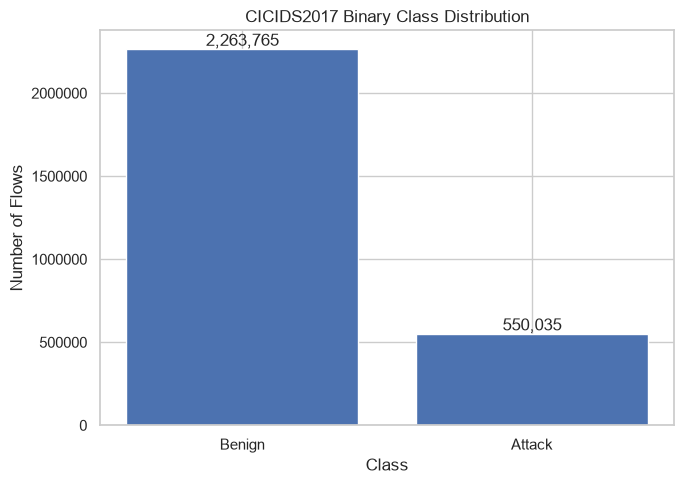

In [3]:
# Read every capture file and keep only files with a usable Label column.
frames = []
for csv_path in csv_files:
    try:
        # UTF-8 handles the normal files; Latin-1 is a fallback for older CICIDS2017 exports.
        frame = pd.read_csv(csv_path, encoding="utf-8-sig", low_memory=False)
    except UnicodeDecodeError:
        frame = pd.read_csv(csv_path, encoding="latin1", low_memory=False)
        print(f"Used Latin-1 fallback for {csv_path.name}")

    # Header whitespace differs between some source files, so normalize before locating Label.
    frame.columns = [str(col).strip() for col in frame.columns]
    label_col = next((col for col in frame.columns if col.lower() == "label"), None)
    if frame.empty or label_col is None:
        print(f"Skipping {csv_path.name}: no usable label column")
        continue
    if label_col != "Label":
        frame = frame.rename(columns={label_col: "Label"})
    frames.append(frame)

if not frames:
    raise ValueError("No valid CICIDS2017 CSV files were found in the data folder.")

# Combine captures into one flow-level dataset for a single, reproducible experiment.
df = pd.concat(frames, ignore_index=True)

# Drop identifiers and timestamps because they describe the capture context rather than general traffic behavior.
metadata_cols = ["Flow ID", "Source IP", "Destination IP", "Timestamp"]
df = df.drop(columns=[col for col in metadata_cols if col in df.columns], errors="ignore")

# Remove duplicate flows and represent invalid numeric values as missing values for later imputation.
df = df.drop_duplicates().replace([np.inf, -np.inf], np.nan)
for col in df.columns:
    if col != "Label":
        df[col] = pd.to_numeric(df[col], errors="coerce")

# Collapse all attack categories into class 1; only the BENIGN category becomes class 0.
df["Label"] = df["Label"].astype(str).str.strip().apply(lambda label: 0 if label == "BENIGN" else 1)
if USE_SAMPLE:
    df = df.sample(frac=SAMPLE_FRAC, random_state=SEED)

print("Cleaned dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())
print("\nLabel distribution:")
print(df["Label"].value_counts().sort_index())

# Visualize the class imbalance before model training.
label_counts = df["Label"].value_counts().sort_index()
plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["Benign", "Attack"],
    [label_counts.get(0, 0), label_counts.get(1, 0)],
)
plt.xlabel("Class")
plt.ylabel("Number of Flows")
plt.title("CICIDS2017 Binary Class Distribution")
plt.ticklabel_format(style="plain", axis="y")
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height, f"{int(height):,}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

## 3. Create stratified train, validation, and test sets

In [4]:
# Separate features from the binary target before creating fixed experiment partitions.
X = df.drop(columns=["Label"])
y = df["Label"].astype(int)

# Keep the class ratio stable in all partitions: 60% train, 20% validation, and 20% test.
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=SEED, stratify=y_temp
)
print("Train/validation/test sizes:", len(X_train), len(X_val), len(X_test))

Train/validation/test sizes: 1688280 562760 562760


## 4. Creating the 1%, 5% and 10% "few-label" splits

In [5]:
# Each budget represents the fraction of training rows whose labels are available.
LABEL_BUDGETS = [0.01, 0.05, 0.10]

# Build deterministic labelled and unlabelled pools from the same training partition.
few_label_splits = {}
for budget in LABEL_BUDGETS:
    # Stratification prevents a small labelled subset from accidentally losing a class.
    X_labelled, X_unlabelled, y_labelled, _ = train_test_split(
        X_train,
        y_train,
        train_size=budget,
        random_state=SEED,
        stratify=y_train,
    )
    few_label_splits[budget] = {
        "X_labelled": X_labelled.copy(),
        "y_labelled": y_labelled.copy(),
        "X_unlabelled": X_unlabelled.copy(),
    }
    print(
        f"{budget:.0%} budget: "
        f"{len(X_labelled):,} labelled rows, "
        f"{len(X_unlabelled):,} unlabelled rows"
    )

# Validation remains fully labelled for model comparison; the test set is reserved for final evaluation.
# The current notebook reports validation metrics so that the test set is not used during development.

1% budget: 16,882 labelled rows, 1,671,398 unlabelled rows
5% budget: 84,414 labelled rows, 1,603,866 unlabelled rows
10% budget: 168,828 labelled rows, 1,519,452 unlabelled rows


## 5. Recreate the baselines using the above Splits

In [6]:
# Use one classifier and one preprocessing policy across all methods for a fair comparison.
def make_baseline_model():
    return Pipeline([
        # Fit imputation only on each method's training data to avoid validation leakage.
        ("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
        # Balanced class weights reduce the effect of the benign/attack imbalance.
        ("model", RandomForestClassifier(
            n_estimators=300,
            random_state=SEED,
            class_weight="balanced",
            n_jobs=-1,
        )),
    ])


def evaluate_model(model, X_eval, y_eval):
    # FAR measures benign flows incorrectly reported as attacks: false positives / all benign flows.
    predictions = model.predict(X_eval)
    probabilities = model.predict_proba(X_eval)[:, 1]
    tn, fp, _, _ = confusion_matrix(
        y_eval,
        predictions,
        labels=[0, 1],
    ).ravel()
    return {
        "accuracy": accuracy_score(y_eval, predictions),
        "macro_f1": f1_score(y_eval, predictions, average="macro"),
        "recall": recall_score(y_eval, predictions, zero_division=0),
        "roc_auc": roc_auc_score(y_eval, probabilities),
        "far": fp / (fp + tn) if (fp + tn) else 0.0,
    }

In [7]:
baseline_results = []
labelled_models = {}

# Upper reference point: train with every available training label.
full_label_model = make_baseline_model()
full_label_model.fit(X_train, y_train)
full_label_metrics = evaluate_model(full_label_model, X_val, y_val)
baseline_results.append({
    "method": "Full-label baseline",
    "label_budget": 1.0,
    **full_label_metrics,
})

# Lower reference points: train with only the labelled subset and ignore the unlabelled pool.
for budget in LABEL_BUDGETS:
    split = few_label_splits[budget]
    labelled_model = make_baseline_model()
    labelled_model.fit(split["X_labelled"], split["y_labelled"])
    labelled_metrics = evaluate_model(labelled_model, X_val, y_val)
    baseline_results.append({
        "method": "Labelled-only baseline",
        "label_budget": budget,
        **labelled_metrics,
    })
    labelled_models[budget] = labelled_model

# Store metrics in a table so every later method can be compared using the same columns.
baseline_results_df = pd.DataFrame(baseline_results)
display(baseline_results_df.round(6))

,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
0,Full-label baseline,1.00,0.999593,0.999353,0.999318,0.999986,0.000340
1,Labelled-only baseline,0.01,0.997100,0.995387,0.991655,0.999896,0.001577
2,Labelled-only baseline,0.05,0.998754,0.998020,0.997073,0.999982,0.000837
3,Labelled-only baseline,0.10,0.998913,0.998271,0.997382,0.999977,0.000716


## 6. Pseudo-Labelling

In [8]:
# A high threshold limits error propagation but may leave more examples unused.
CONFIDENCE_THRESHOLD = 0.95
MAX_ROUNDS = 10


def pseudo_label_round(model, X_unlabelled, threshold):
    """Predict on the unlabelled pool; return confident rows and their pseudo-labels."""
    probabilities = model.predict_proba(X_unlabelled) #Get predicted probabilites for each class (0 = benign, 1 = attack) for each row in the unlabelled datase
    predicted_labels = np.argmax(probabilities, axis=1) # Get the predicted class label for each row in the unlabelled dataset (0 = benign, 1 = attack) by taking the index of the maximum probability for each row
    confidence = np.max(probabilities, axis=1) # Get the maximum predicted probability for each row in the unlabelled dataset (i.e., the confidence of the prediction)
    confident_mask = confidence >= threshold # Get a boolean mask indicating which rows have confidence above the threshold
    return X_unlabelled[confident_mask], predicted_labels[confident_mask], confident_mask 

def run_pseudo_labelling(X_labelled, y_labelled, X_unlabelled,
                          threshold=CONFIDENCE_THRESHOLD, max_rounds=MAX_ROUNDS):
    X_train_growing = X_labelled.copy() # Create a copy of the labelled data to use as the initial training set
    y_train_growing = y_labelled.copy() # Create a copy of the labelled labels to use as the initial training labels
    X_pool_remaining = X_unlabelled.copy() # Create a copy of the unlabelled data to use as the remaining pool

    round_history = []

    for round_num in range(1, max_rounds + 1): 
        model = make_baseline_model() # Create a new instance of the baseline model for each round to avoid overfitting to previous rounds
        model.fit(X_train_growing, y_train_growing)

        if len(X_pool_remaining) == 0: # No more unlabelled rows to process; stop early.
            break

        # Predict on the remaining unlabelled pool and identify confident pseudo-labels.
        X_confident, y_confident, confident_mask = pseudo_label_round( 
            model, X_pool_remaining, threshold
        ) 
        # Record the results for this round.
        round_history.append({
            "round": round_num,
            "labelled_pool_size": len(X_train_growing),
            "newly_pseudo_labelled": len(X_confident),
            "remaining_unlabelled": len(X_pool_remaining) - len(X_confident),
        })
        # Print a summary of the round's results.
        print(f"Round {round_num}: added {len(X_confident)} confident pseudo-labels "
              f"({len(X_pool_remaining) - len(X_confident)} unlabelled remain)")
        
        if len(X_confident) == 0:
            # No more confident guesses available; stop early.
            break

        # Add the confident pseudo-labelled rows to the training set.
        X_train_growing = pd.concat([X_train_growing, X_confident], ignore_index=True)
        y_train_growing = np.concatenate([y_train_growing, y_confident])

        # Remove them from the remaining pool so they aren't re-labelled next round.
        X_pool_remaining = X_pool_remaining[~confident_mask].reset_index(drop=True)

    # Final retrain on the fully grown labelled set.
    final_model = make_baseline_model()
    final_model.fit(X_train_growing, y_train_growing)
    return final_model, pd.DataFrame(round_history)

In [9]:
pseudo_label_results = []
pseudo_label_models = {}

# Run the same iterative pseudo-labelling procedure independently for each label budget.
for budget in LABEL_BUDGETS:
    # Get the labelled and unlabelled splits for this budget.
    split = few_label_splits[budget]
    # Print a header to indicate the start of pseudo-labelling for this budget.
    print(f"\n--- Pseudo-labelling at {budget:.0%} label budget ---") 
    # Run the pseudo-labelling process and evaluate the final model on the validation set.
    pl_model, pl_history = run_pseudo_labelling(
        split["X_labelled"].reset_index(drop=True),
        split["y_labelled"].reset_index(drop=True),
        split["X_unlabelled"].reset_index(drop=True),
        threshold=CONFIDENCE_THRESHOLD,
    )
    # Store the pseudo-labeled model for this budget.
    pseudo_label_models[budget] = pl_model
    # Evaluate on the validation set.
    pl_metrics = evaluate_model(pl_model, X_val, y_val)
    # Store the metrics for this budget in the results table.
    pseudo_label_results.append({
        "method": "Pseudo-labelling",
        "label_budget": budget,
        **pl_metrics,
    })

# Display the pseudo-labelling results in a DataFrame for easy viewing.
pseudo_label_results_df = pd.DataFrame(pseudo_label_results)
display(pseudo_label_results_df.round(4))

# Combine supervised baselines and pseudo-labelling into the running comparison table.
all_results_df = pd.concat([baseline_results_df, pseudo_label_results_df], ignore_index=True)
display(all_results_df.sort_values(["label_budget", "method"]).round(6))


--- Pseudo-labelling at 1% label budget ---
Round 1: added 1614059 confident pseudo-labels (57339 unlabelled remain)
Round 2: added 25530 confident pseudo-labels (31809 unlabelled remain)
Round 3: added 7235 confident pseudo-labels (24574 unlabelled remain)
Round 4: added 3343 confident pseudo-labels (21231 unlabelled remain)
Round 5: added 1470 confident pseudo-labels (19761 unlabelled remain)
Round 6: added 1139 confident pseudo-labels (18622 unlabelled remain)
Round 7: added 576 confident pseudo-labels (18046 unlabelled remain)
Round 8: added 606 confident pseudo-labels (17440 unlabelled remain)
Round 9: added 349 confident pseudo-labels (17091 unlabelled remain)
Round 10: added 246 confident pseudo-labels (16845 unlabelled remain)

--- Pseudo-labelling at 5% label budget ---
Round 1: added 1580816 confident pseudo-labels (23050 unlabelled remain)
Round 2: added 8342 confident pseudo-labels (14708 unlabelled remain)
Round 3: added 2200 confident pseudo-labels (12508 unlabelled rema

,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
0,Pseudo-labelling,0.01,0.9967,0.9948,0.9872,0.9982,0.0010
1,Pseudo-labelling,0.05,0.9985,0.9975,0.9954,0.9997,0.0008
2,Pseudo-labelling,0.10,0.9988,0.9981,0.9966,0.9998,0.0007


,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
1,Labelled-only baseline,0.01,0.997100,0.995387,0.991655,0.999896,0.001577
4,Pseudo-labelling,0.01,0.996725,0.994777,0.987228,0.998178,0.000967
2,Labelled-only baseline,0.05,0.998754,0.998020,0.997073,0.999982,0.000837
5,Pseudo-labelling,0.05,0.998452,0.997539,0.995446,0.999741,0.000817
3,Labelled-only baseline,0.10,0.998913,0.998271,0.997382,0.999977,0.000716
6,Pseudo-labelling,0.10,0.998804,0.998098,0.996609,0.999789,0.000663
0,Full-label baseline,1.00,0.999593,0.999353,0.999318,0.999986,0.000340


## 7. Co-training

Co-training maintains two Random Forest models trained on disjoint feature views. Each model can teach the other only when its prediction is confident; when both models are confident, the example is shared only when their predicted labels agree. This reduces dependence on a single model's mistakes while expanding both training sets.

In [10]:
# Use the same threshold and max rounds for co-training as for pseudo-labelling.
CO_TRAIN_THRESHOLD = CONFIDENCE_THRESHOLD
CO_TRAIN_MAX_ROUNDS = MAX_ROUNDS

# Split the features into two disjoint views for co-training.
def make_feature_views(X):
    columns = list(X.columns)
    midpoint = len(columns) // 2
    view_1 = columns[:midpoint]
    view_2 = columns[midpoint:]
    return view_1, view_2

view_1, view_2 = make_feature_views(X_train)

# Quick sanity check: the two views should be disjoint and cover all features.
print("----Debug prints----")
print("Total features:", X_train.shape[1])
print("View 1:", len(view_1))
print("View 2:", len(view_2))
print("\nFirst features in view 1:")
print(view_1[:5])
print("\nFirst features in view 2:")
print(view_2[:5])
print("--------------------")

# Get predictions and confidence scores from both models on the unlabelled pool.
def get_co_training_predictions(model_1, model_2, X_unlabelled, view_1, view_2, threshold):
    # Each model predicts on its own view of the unlabelled data.
    probabilities_1 = model_1.predict_proba(X_unlabelled[view_1])
    probabilities_2 = model_2.predict_proba(X_unlabelled[view_2])
    # Determine the predicted labels and confidence for each model.
    predicted_labels_1 = np.argmax(probabilities_1, axis=1)
    predicted_labels_2 = np.argmax(probabilities_2, axis=1)
    # Determine the confidence for each model's predictions. The confidence is the maximum probability assigned to any class for each sample.
    confidence_1 = np.max(probabilities_1, axis=1)
    confidence_2 = np.max(probabilities_2, axis=1)
    # Determine which predictions are confident enough to be used for pseudo-labelling.
    confident_1 = confidence_1 >= threshold
    confident_2 = confidence_2 >= threshold

    return (
        predicted_labels_1,
        predicted_labels_2,
        confidence_1,
        confidence_2,
        confident_1,
        confident_2
    )

# Determine which samples each model can teach to the other based on confidence.
def get_teaching_masks(predicted_labels_1, predicted_labels_2, confident_1, confident_2):
    teach_2_mask = confident_1 & ~confident_2 # Model 1 can teach Model 2 if Model 1 is confident and Model 2 is not.
    teach_1_mask = confident_2 & ~confident_1 # Model 2 can teach Model 1 if Model 2 is confident and Model 1 is not.

    # If both models are confident and agree on the label, they can teach each other.
    agree_mask = (confident_1 & confident_2 & (predicted_labels_1 == predicted_labels_2))

    # Update the teaching masks to include the samples where both models agree and are confident.
    teach_1_mask = teach_1_mask | agree_mask
    teach_2_mask = teach_2_mask | agree_mask

    return teach_1_mask, teach_2_mask

def run_co_training(X_labelled, y_labelled, X_unlabelled, threshold=CO_TRAIN_THRESHOLD, max_rounds=CO_TRAIN_MAX_ROUNDS):
    # Split the features into two disjoint views for co-training.
    view_1, view_2 = make_feature_views(X_labelled)

    # Initialize the training sets for both models with the labelled data.
    X_train_1 = X_labelled.copy()
    y_train_1 = y_labelled.copy()
    X_train_2 = X_labelled.copy()
    y_train_2 = y_labelled.copy()

    # Initialize the remaining unlabelled pool.
    X_pool = X_unlabelled.copy()

    # Initialize a list to keep track of the history of each round, including the number of samples added and the remaining unlabelled samples.
    round_history = []

    # Run the co-training process for a specified number of rounds.
    for round_num in range(1, max_rounds + 1):
        # Train both models on their respective views of the training data.
        model_1 = make_baseline_model()
        model_2 = make_baseline_model()

        # Fit the models with the current training data.
        model_1.fit(X_train_1[view_1], y_train_1)
        model_2.fit(X_train_2[view_2], y_train_2)

        # Stop if there are no more unlabelled samples to process.
        if len(X_pool) == 0:
            break

        # Get predictions and confidence scores from both models on the unlabelled pool.
        (
            predicted_labels_1,
            predicted_labels_2,
            confidence_1,
            confidence_2,
            confident_1,
            confident_2
        ) = get_co_training_predictions(model_1, model_2, X_pool, view_1, view_2, threshold)

        # Determine which samples each model can teach to the other based on confidence and agreement.
        teach_1_mask, teach_2_mask = get_teaching_masks(predicted_labels_1, predicted_labels_2, confident_1, confident_2)

        # Select the samples that each model can teach to the other based on the teaching masks.
        X_teach_1 = X_pool[teach_1_mask]
        X_teach_2 = X_pool[teach_2_mask]

        y_teach_1 = predicted_labels_2[teach_1_mask]  # Model 2 teaches Model 1
        y_teach_2 = predicted_labels_1[teach_2_mask]  # Model 1 teaches Model 2

        # Add the newly pseudo-labelled samples to Model 1's training set.
        if len(X_teach_1) > 0:
            X_train_1 = pd.concat([X_train_1, X_teach_1], ignore_index=True)
            y_train_1 = np.concatenate([y_train_1, y_teach_1])

        # Add the newly pseudo-labelled samples to Model 2's training set.
        if len(X_teach_2) > 0:
            X_train_2 = pd.concat([X_train_2, X_teach_2], ignore_index=True)
            y_train_2 = np.concatenate([y_train_2, y_teach_2])

        # Remove the newly pseudo-labelled samples from the unlabelled pool to avoid re-labelling them in future rounds.
        used_mask = teach_1_mask | teach_2_mask
        X_pool = X_pool[~used_mask].copy()

        # Record the history of this round, including the number of samples added and the remaining unlabelled samples.
        round_history.append({
            "round": round_num,
            "taught_to_model_1": int(teach_1_mask.sum()),
            "taught_to_model_2": int(teach_2_mask.sum()),
            "remaining_unlabelled": len(X_pool),
        })

        # No more confident predictions available, break loop early.
        if used_mask.sum() == 0:
            break

    # Final retrain on the fully grown labelled sets for both models.
    final_model_1 = make_baseline_model()
    final_model_2 = make_baseline_model()
    final_model_1.fit(X_train_1[view_1], y_train_1)
    final_model_2.fit(X_train_2[view_2], y_train_2)

    return final_model_1, final_model_2, view_1, view_2, pd.DataFrame(round_history)

def evaluate_co_training_models(model_1, model_2, view_1, view_2, X, y):
    # Get the probability of class 1 (attack) from both models
    probabilities_1 = model_1.predict_proba(X[view_1])[:, 1]
    probabilities_2 = model_2.predict_proba(X[view_2])[:, 1]

    # Average the probabilities from both models to get a combined prediction
    probabilities = (probabilities_1 + probabilities_2) / 2

    # Convert probabilities to binary predictions using a threshold of 0.5
    predictions = (probabilities >= 0.5).astype(int)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y, predictions)
    macro_f1 = f1_score(y, predictions, average="macro")
    recall = recall_score(y, predictions)
    roc_auc = roc_auc_score(y, probabilities)

    tn, fp, fn, tp = confusion_matrix(y, predictions).ravel()
    far = fp / (fp + tn)

    return {
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "recall": recall,
        "roc_auc": roc_auc,
        "far": far,
    }

----Debug prints----
Total features: 80
View 1: 40
View 2: 40

First features in view 1:
['Source Port', 'Destination Port', 'Protocol', 'Flow Duration', 'Total Fwd Packets']

First features in view 2:
['Min Packet Length', 'Max Packet Length', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance']
--------------------


In [11]:
# Run co-training for each label budget and evaluate the results

co_training_results = []
co_training_histories = {}
co_training_models = {}

for budget in LABEL_BUDGETS:
    print(f"\n--- Co-training at {budget:.0%} label budget ---")
    split = few_label_splits[budget]
    (model_1, model_2, view_1, view_2, history) = run_co_training(
        split["X_labelled"],
        split["y_labelled"],
        split["X_unlabelled"],
    )
    co_training_models[budget] = {"model_1": model_1, "model_2": model_2, "view_1": view_1, "view_2": view_2}
    metrics = evaluate_co_training_models(model_1, model_2, view_1, view_2, X_val, y_val)
    metrics["method"] = "Co-training"
    metrics["label_budget"] = budget
    co_training_results.append(metrics)
    co_training_histories[budget] = history
    print(history)
    print(metrics)
co_training_results_df = pd.DataFrame(co_training_results)
co_training_results_df


--- Co-training at 1% label budget ---
   round  taught_to_model_1  taught_to_model_2  remaining_unlabelled
0      1            1621143            1609732                 20754
1      2               8698               8266                  9584
2      3                914               1180                  8048
3      4                360                179                  7603
4      5                385                333                  6971
5      6                300                 39                  6638
6      7                 58                 80                  6514
7      8                159                239                  6246
8      9                 64                 14                  6175
9     10                 18                 13                  6144
{'accuracy': 0.9962097519368825, 'macro_f1': 0.9939603289939813, 'recall': 0.9871462725099311, 'roc_auc': 0.9986838397490365, 'far': np.float64(0.0015880623651306563), 'method': 'Co-training', 'label_b

,accuracy,macro_f1,recall,roc_auc,far,method,label_budget
0,0.996210,0.993960,0.987146,0.998684,0.001588,Co-training,0.01
1,0.998642,0.997843,0.997000,0.999803,0.000959,Co-training,0.05
2,0.998689,0.997916,0.997237,0.999867,0.000959,Co-training,0.10


In [12]:
# Add co-training results to the previous baseline and pseudo-labelling results.
step4_results_df = pd.concat(
    [all_results_df, co_training_results_df],
    ignore_index=True
)

step4_results_df

,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
0,Full-label baseline,1.00,0.999593,0.999353,0.999318,0.999986,0.000340
1,Labelled-only baseline,0.01,0.997100,0.995387,0.991655,0.999896,0.001577
2,Labelled-only baseline,0.05,0.998754,0.998020,0.997073,0.999982,0.000837
3,Labelled-only baseline,0.10,0.998913,0.998271,0.997382,0.999977,0.000716
4,Pseudo-labelling,0.01,0.996725,0.994777,0.987228,0.998178,0.000967
5,Pseudo-labelling,0.05,0.998452,0.997539,0.995446,0.999741,0.000817
6,Pseudo-labelling,0.10,0.998804,0.998098,0.996609,0.999789,0.000663
7,Co-training,0.01,0.996210,0.993960,0.987146,0.998684,0.001588
8,Co-training,0.05,0.998642,0.997843,0.997000,0.999803,0.000959
9,Co-training,0.10,0.998689,0.997916,0.997237,0.999867,0.000959


## 8. Ablation study - confidence threshold

The ablation varies the pseudo-labelling confidence threshold while keeping the data splits, model, and number of rounds fixed. Comparing the resulting validation metrics shows how conservative or permissive pseudo-label selection affects performance.

In [13]:
# Confidence thresholds for ablation study: 90%, 95%, and 99%.
ABLATION_THRESHOLDS = [0.90, 0.95, 0.99]

ablation_results = []

for threshold in ABLATION_THRESHOLDS:
    print(f"\n--- Ablation study at {threshold:.0%} confidence threshold ---")
    for budget in LABEL_BUDGETS:
        print(f"\nLabel budget: {budget:.0%}")
        split = few_label_splits[budget]
        model, history = run_pseudo_labelling(split["X_labelled"], split["y_labelled"], split["X_unlabelled"], threshold=threshold, max_rounds=MAX_ROUNDS)
        metrics = evaluate_model(model, X_val, y_val)
        metrics["threshold"] = threshold
        metrics["label_budget"] = budget
        ablation_results.append(metrics)
ablation_results_df = pd.DataFrame(ablation_results)
ablation_results_df


--- Ablation study at 90% confidence threshold ---

Label budget: 1%
Round 1: added 1639339 confident pseudo-labels (32059 unlabelled remain)
Round 2: added 15809 confident pseudo-labels (16250 unlabelled remain)
Round 3: added 3503 confident pseudo-labels (12747 unlabelled remain)
Round 4: added 909 confident pseudo-labels (11838 unlabelled remain)
Round 5: added 625 confident pseudo-labels (11213 unlabelled remain)
Round 6: added 311 confident pseudo-labels (10902 unlabelled remain)
Round 7: added 204 confident pseudo-labels (10698 unlabelled remain)
Round 8: added 151 confident pseudo-labels (10547 unlabelled remain)
Round 9: added 157 confident pseudo-labels (10390 unlabelled remain)
Round 10: added 227 confident pseudo-labels (10163 unlabelled remain)

Label budget: 5%
Round 1: added 1591273 confident pseudo-labels (12593 unlabelled remain)
Round 2: added 4396 confident pseudo-labels (8197 unlabelled remain)
Round 3: added 1311 confident pseudo-labels (6886 unlabelled remain)
Rou

,accuracy,macro_f1,recall,roc_auc,far,threshold,label_budget
0,0.996583,0.994551,0.987146,0.997365,0.001124,0.90,0.01
1,0.998379,0.997422,0.995046,0.999579,0.000811,0.90,0.05
2,0.998761,0.998030,0.996382,0.999686,0.000660,0.90,0.10
3,0.996725,0.994777,0.987228,0.998178,0.000967,0.95,0.01
4,0.998452,0.997539,0.995446,0.999741,0.000817,0.95,0.05
5,0.998804,0.998098,0.996609,0.999789,0.000663,0.95,0.10
6,0.996773,0.994860,0.989101,0.999272,0.001363,0.99,0.01
7,0.998584,0.997748,0.996273,0.999928,0.000855,0.99,0.05
8,0.998891,0.998237,0.997191,0.999916,0.000696,0.99,0.10


## 9. Final evalutaion on test set

In [14]:
final_test_results = []

metrics = evaluate_model(full_label_model, X_test, y_test)

final_test_results.append({
    "method": "Full-label baseline",
    "label_budget": 1.0,
    **metrics,
})

# Labelled-only baselines for each budget, evaluated on the test set.
for budget in LABEL_BUDGETS:
    metrics = evaluate_model(labelled_models[budget], X_test, y_test)
    final_test_results.append({
        "method": "Labelled-only baseline",
        "label_budget": budget,
        **metrics,
    })

# Pseudo-labelling results for each budget, evaluated on the test set.
for budget in LABEL_BUDGETS:
    metrics = evaluate_model(pseudo_label_models[budget], X_test, y_test)
    final_test_results.append({
        "method": "Pseudo-labelling",
        "label_budget": budget,
        **metrics,
    })

# Co-training results for each budget, evaluated on the test set.
for budget in LABEL_BUDGETS:
    saved_models = co_training_models[budget]
    metrics = evaluate_co_training_models(
        saved_models["model_1"],
        saved_models["model_2"],
        saved_models["view_1"],
        saved_models["view_2"],
        X_test,
        y_test,
    )
    final_test_results.append({
        "method": "Co-training",
        "label_budget": budget,
        **metrics,
    })

# Display the final test results in a DataFrame for easy viewing.
final_test_results_df = pd.DataFrame(final_test_results)
display(final_test_results_df.sort_values(["label_budget", "method"]).round(6))

,method,label_budget,accuracy,macro_f1,recall,roc_auc,far
7,Co-training,0.01,0.996153,0.993872,0.987519,0.998726,0.001749
1,Labelled-only baseline,0.01,0.997132,0.995439,0.992001,0.999886,0.001621
4,Pseudo-labelling,0.01,0.996668,0.994687,0.987355,0.998228,0.001069
8,Co-training,0.05,0.998634,0.997829,0.997237,0.999828,0.001027
2,Labelled-only baseline,0.05,0.998765,0.998038,0.997418,0.999977,0.000908
5,Pseudo-labelling,0.05,0.998527,0.997658,0.996082,0.999707,0.000879
9,Co-training,0.10,0.998687,0.997914,0.997464,0.999883,0.001016
3,Labelled-only baseline,0.10,0.998971,0.998365,0.997837,0.999973,0.000753
6,Pseudo-labelling,0.10,0.998865,0.998195,0.997037,0.999756,0.000691
0,Full-label baseline,1.00,0.999606,0.999373,0.999382,0.999987,0.000340


## 10. Comparison Curve

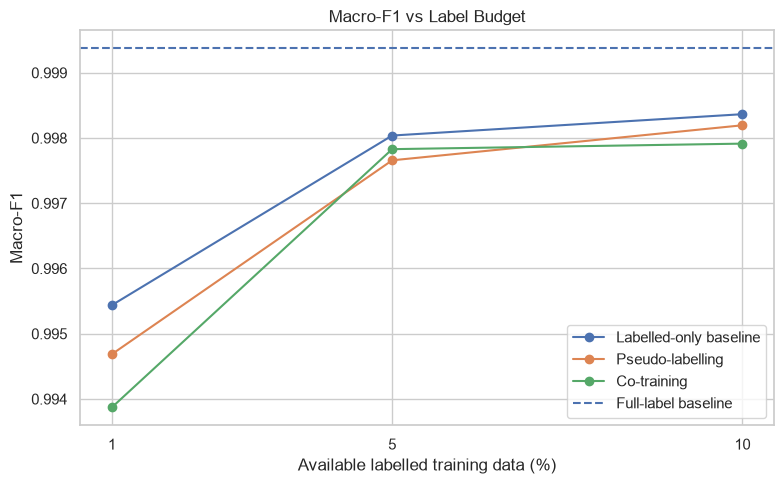

In [15]:
# Macro-F1 vs label budget Comparison curve

plt.figure(figsize=(8, 5))

# Few-label supervised baseline
few_baseline = final_test_results_df[
    final_test_results_df["method"] == "Labelled-only baseline"
].sort_values("label_budget")

plt.plot(
    few_baseline["label_budget"] * 100,
    few_baseline["macro_f1"],
    marker="o",
    label="Labelled-only baseline"
)

# Pseudo-labelling
pseudo = final_test_results_df[
    final_test_results_df["method"] == "Pseudo-labelling"
].sort_values("label_budget")

plt.plot(
    pseudo["label_budget"] * 100,
    pseudo["macro_f1"],
    marker="o",
    label="Pseudo-labelling"
)

# Co-training
co_train = final_test_results_df[
    final_test_results_df["method"] == "Co-training"
].sort_values("label_budget")

plt.plot(
    co_train["label_budget"] * 100,
    co_train["macro_f1"],
    marker="o",
    label="Co-training"
)

# Full-label upper baseline
full_f1 = final_test_results_df.loc[
    final_test_results_df["method"] == "Full-label baseline",
    "macro_f1"
].iloc[0]

plt.axhline(
    y=full_f1,
    linestyle="--",
    label="Full-label baseline"
)

plt.xlabel("Available labelled training data (%)")
plt.ylabel("Macro-F1")
plt.title("Macro-F1 vs Label Budget")
plt.xticks([1, 5, 10])
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()